
Algorithm: Logistic Regression
Accuracy: 0.9824561403508771

Algorithm: KNN
Accuracy: 0.956140350877193

Algorithm: Decision Tree
Accuracy: 0.9122807017543859

Algorithm: Random Forest
Accuracy: 0.956140350877193

Algorithm: Naive Bayes
Accuracy: 0.9385964912280702

Algorithm: SVM
Accuracy: 0.9824561403508771

Classification Algorithm Comparison
             Algorithm  Accuracy
0  Logistic Regression  0.982456
1                  KNN  0.956140
2        Decision Tree  0.912281
3        Random Forest  0.956140
4          Naive Bayes  0.938596
5                  SVM  0.982456


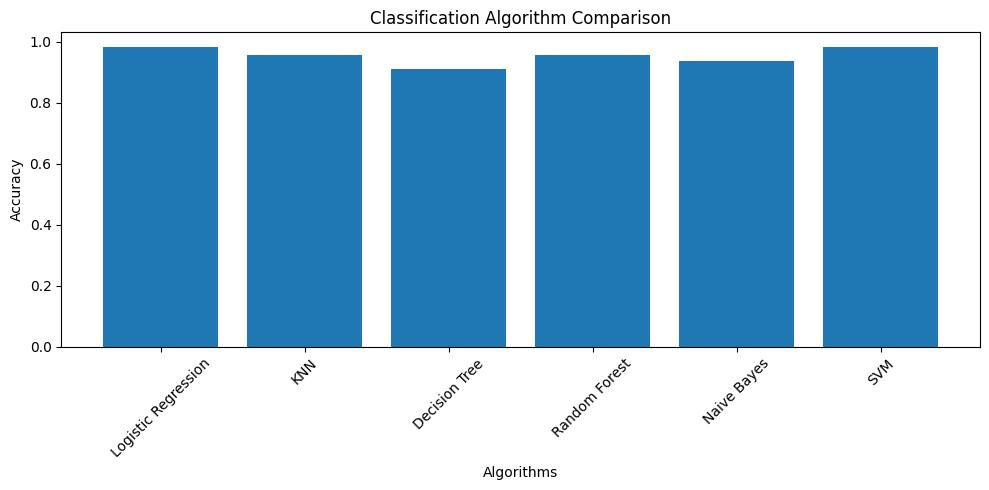


Best Performing Algorithm: Logistic Regression


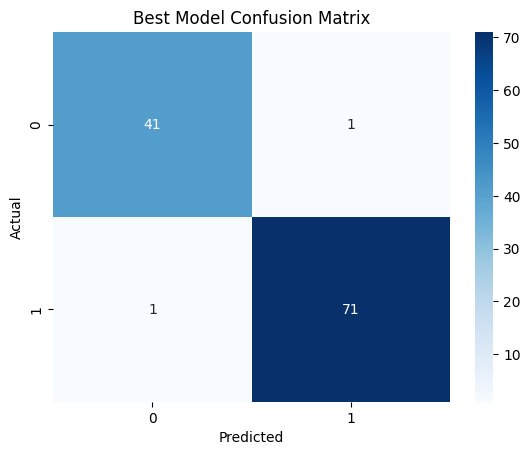

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC

from sklearn.metrics import accuracy_score, confusion_matrix

# Load dataset
data = load_breast_cancer()

X = data.data
y = data.target

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Create classification models
models = {
    'Logistic Regression': make_pipeline(
        StandardScaler(), LogisticRegression(max_iter=1000)
    ),

    'KNN': make_pipeline(
        StandardScaler(), KNeighborsClassifier(n_neighbors=5)
    ),

    'Decision Tree': DecisionTreeClassifier(random_state=42),

    'Random Forest': RandomForestClassifier(random_state=42),

    'Naive Bayes': GaussianNB(),

    'SVM': make_pipeline(
        StandardScaler(), SVC()
    )
}

# Compare accuracy
results = {}

for name, model in models.items():

    # Train model
    model.fit(X_train, y_train)

    # Predict
    y_pred = model.predict(X_test)

    # Calculate accuracy
    accuracy = accuracy_score(y_test, y_pred)

    results[name] = accuracy

    print("\nAlgorithm:", name)
    print("Accuracy:", accuracy)

# Display comparison table
print("\nClassification Algorithm Comparison")

result_df = pd.DataFrame(
    list(results.items()),
    columns=['Algorithm', 'Accuracy']
)

print(result_df)

# Plot accuracy comparison
plt.figure(figsize=(10, 5))

plt.bar(result_df['Algorithm'], result_df['Accuracy'])

plt.title("Classification Algorithm Comparison")
plt.xlabel("Algorithms")
plt.ylabel("Accuracy")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Find best algorithm
best_model = max(results, key=results.get)

print("\nBest Performing Algorithm:", best_model)

# Confusion matrix for best model
best = models[best_model]
y_pred = best.predict(X_test)

cm = confusion_matrix(y_test, y_pred)

sns.heatmap(cm, annot=True, cmap='Blues', fmt='d')

plt.title("Best Model Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()